In [48]:

from pathlib import Path

# Create the main project folder in Downloads
project_dir = Path.home() / "Downloads" / "PRCP-1020-HousePricePrediction"

# Define the required folders
folders = [
    project_dir / "data" / "raw",
    project_dir / "models",
    project_dir / "outputs"
]

# Create all folders automatically
for folder in folders:
    folder.mkdir(parents=True, exist_ok=True)
    print("Folder ready:", folder)

print("\nProject folder structure created successfully!")


Folder ready: C:\Users\amrut\Downloads\PRCP-1020-HousePricePrediction\data\raw
Folder ready: C:\Users\amrut\Downloads\PRCP-1020-HousePricePrediction\models
Folder ready: C:\Users\amrut\Downloads\PRCP-1020-HousePricePrediction\outputs

Project folder structure created successfully!


In [49]:

from pathlib import Path
import shutil

# Original dataset location
source_file = (
    Path.home()
    / "Downloads"
    / "PRCP-1020-HousePricePred"
    / "Data"
    / "data.csv"
)

# Destination inside our new project
project_dir = (
    Path.home()
    / "Downloads"
    / "PRCP-1020-HousePricePrediction"
)

destination_file = project_dir / "data" / "raw" / "data.csv"

# Verify and copy
if source_file.exists():
    shutil.copy2(source_file, destination_file)
    print("Dataset copied successfully!")
    print("Saved at:", destination_file)
    print("File size:", round(destination_file.stat().st_size / 1024, 2), "KB")
else:
    print("Dataset not found. Please check the source path.")


Dataset copied successfully!
Saved at: C:\Users\amrut\Downloads\PRCP-1020-HousePricePrediction\data\raw\data.csv
File size: 449.88 KB


In [50]:

import pandas as pd
from pathlib import Path

project_dir = Path.home() / "Downloads" / "PRCP-1020-HousePricePrediction"
dataset_path = project_dir / "data" / "raw" / "data.csv"

df = pd.read_csv(dataset_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()


Dataset loaded successfully!
Dataset shape: (1460, 81)

First 5 rows:


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000



Column names:
['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'Pool

In [51]:

# STEP 6: DATA QUALITY AUDIT

import pandas as pd
import numpy as np

# 1. Dataset dimensions
print("1. DATASET DIMENSIONS")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# 2. Duplicate records
print("\n2. DUPLICATE RECORDS")
print("Duplicate rows:", df.duplicated().sum())

# 3. Missing values
print("\n3. MISSING VALUES")
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if missing.empty:
    print("No missing values found.")
else:
    display(missing.to_frame(name="Missing_Count"))

# 4. Data types
print("\n4. DATA TYPES")
display(df.dtypes.value_counts().to_frame(name="Column_Count"))

# 5. Target variable check
print("\n5. TARGET VARIABLE CHECK")
if "SalePrice" in df.columns:
    print("SalePrice exists.")
    print(df["SalePrice"].describe())
else:
    print("SalePrice was not found. Check the column names.")

# 6. Dataset preview
print("\n6. SAMPLE RECORDS")
display(df.head())


1. DATASET DIMENSIONS
Rows: 1460
Columns: 81

2. DUPLICATE RECORDS
Duplicate rows: 0

3. MISSING VALUES


,Missing_Count
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
MasVnrType,872
FireplaceQu,690
LotFrontage,259
GarageType,81
GarageYrBlt,81
GarageFinish,81



4. DATA TYPES


,Column_Count
str,43
int64,35
float64,3



5. TARGET VARIABLE CHECK
SalePrice exists.
count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

6. SAMPLE RECORDS


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000



## 1. Business Understanding and Initial Data Audit

### Objective
The objective of this project is to develop a machine learning regression model that predicts residential house sale prices using property characteristics.

### Initial Dataset Findings
- The dataset contains 1,460 records and 81 columns.
- The target variable is SalePrice.
- No exact duplicate rows were detected.
- Multiple features contain missing values, requiring investigation and appropriate preprocessing.
- SalePrice has a mean of approximately $180,921 and a median of $163,000.

### Initial Data Quality Assessment
Missing values will not be handled using a single strategy without examining their meaning. Some missing entries may represent the absence of a property feature, while others may indicate unavailable information.

The dataset will be explored before preprocessing. All learned preprocessing operations will subsequently be fitted on training data only to avoid data leakage.


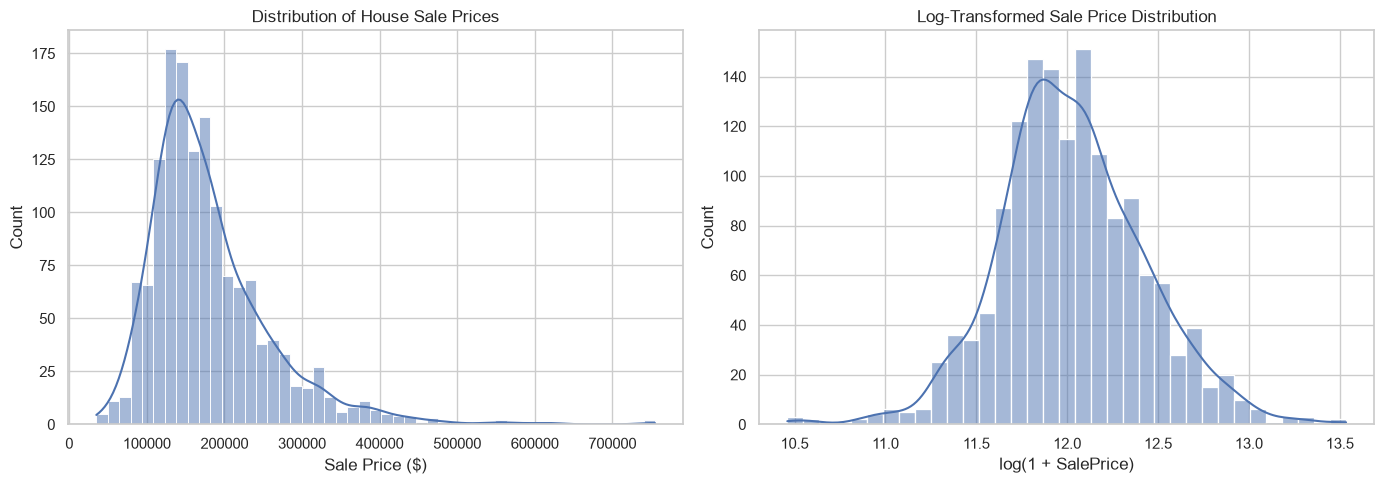

SalePrice skewness: 1.883
SalePrice median: 163000.0
SalePrice mean: 180921.2


In [52]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Distribution of house sale prices
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=df,
    x="SalePrice",
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Distribution of House Sale Prices")
axes[0].set_xlabel("Sale Price ($)")

# Log transformation helps inspect right-skewed prices
sns.histplot(
    x=np.log1p(df["SalePrice"]),
    kde=True,
    ax=axes[1]
)
axes[1].set_title("Log-Transformed Sale Price Distribution")
axes[1].set_xlabel("log(1 + SalePrice)")

plt.tight_layout()
plt.show()

# 2. Key target statistics
print("SalePrice skewness:", round(df["SalePrice"].skew(), 3))
print("SalePrice median:", df["SalePrice"].median())
print("SalePrice mean:", round(df["SalePrice"].mean(), 2))



### EDA Finding: Sale Price Distribution

The SalePrice variable has a positive skewness of 1.883. Its mean is approximately $180,921.20, while its median is $163,000. The higher mean indicates that relatively expensive properties pull the average upward.

A log transformation will be investigated as a potential modeling strategy. Its usefulness will be assessed through validation rather than assumed in advance. High-priced observations will be investigated before deciding whether any treatment is necessary.


,Missing_Count,Missing_Percentage
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


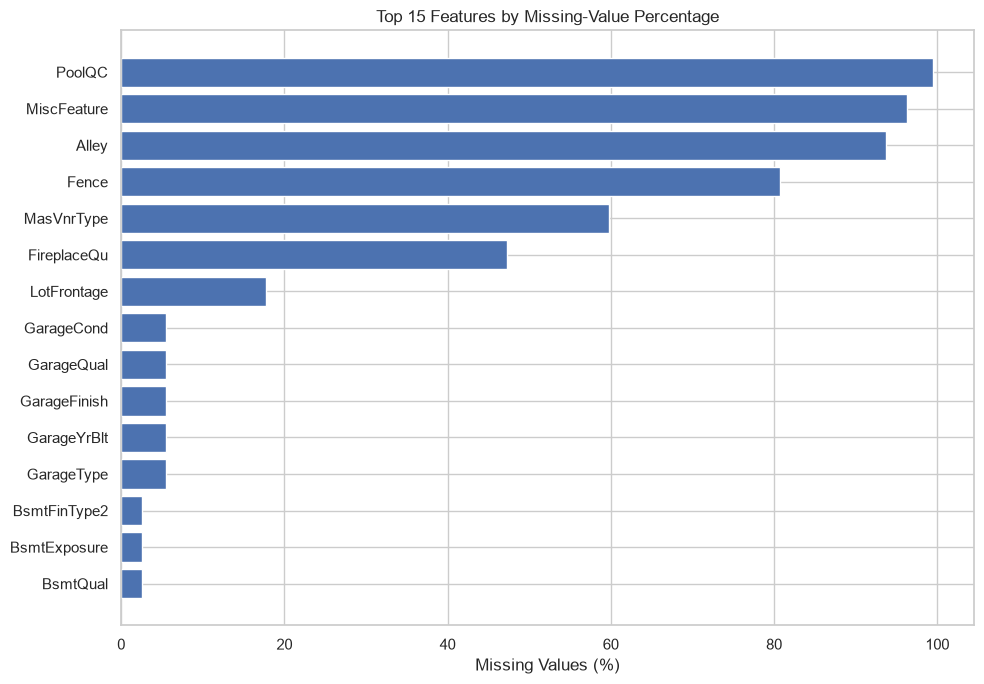

In [53]:

# Missing-value audit with percentages

missing_audit = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": df.isnull().mean() * 100
})

missing_audit = (
    missing_audit[missing_audit["Missing_Count"] > 0]
    .sort_values("Missing_Percentage", ascending=False)
)

display(missing_audit.round(2))

# Visualize the 15 columns with the most missing values
top_missing = missing_audit.head(15).sort_values(
    "Missing_Percentage"
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_missing.index,
    top_missing["Missing_Percentage"]
)
plt.xlabel("Missing Values (%)")
plt.title("Top 15 Features by Missing-Value Percentage")
plt.tight_layout()
plt.show()


Selected feature summaries:


,OverallQual,GrLivArea,GarageCars,TotalBsmtSF,SalePrice
count,1460.00,1460.00,1460.00,1460.00,1460.0
mean,6.10,1515.46,1.77,1057.43,180921.2
std,1.38,525.48,0.75,438.71,79442.5
min,1.00,334.00,0.00,0.00,34900.0
25%,5.00,1129.50,1.00,795.75,129975.0
50%,6.00,1464.00,2.00,991.50,163000.0
75%,7.00,1776.75,2.00,1298.25,214000.0
max,10.00,5642.00,4.00,6110.00,755000.0


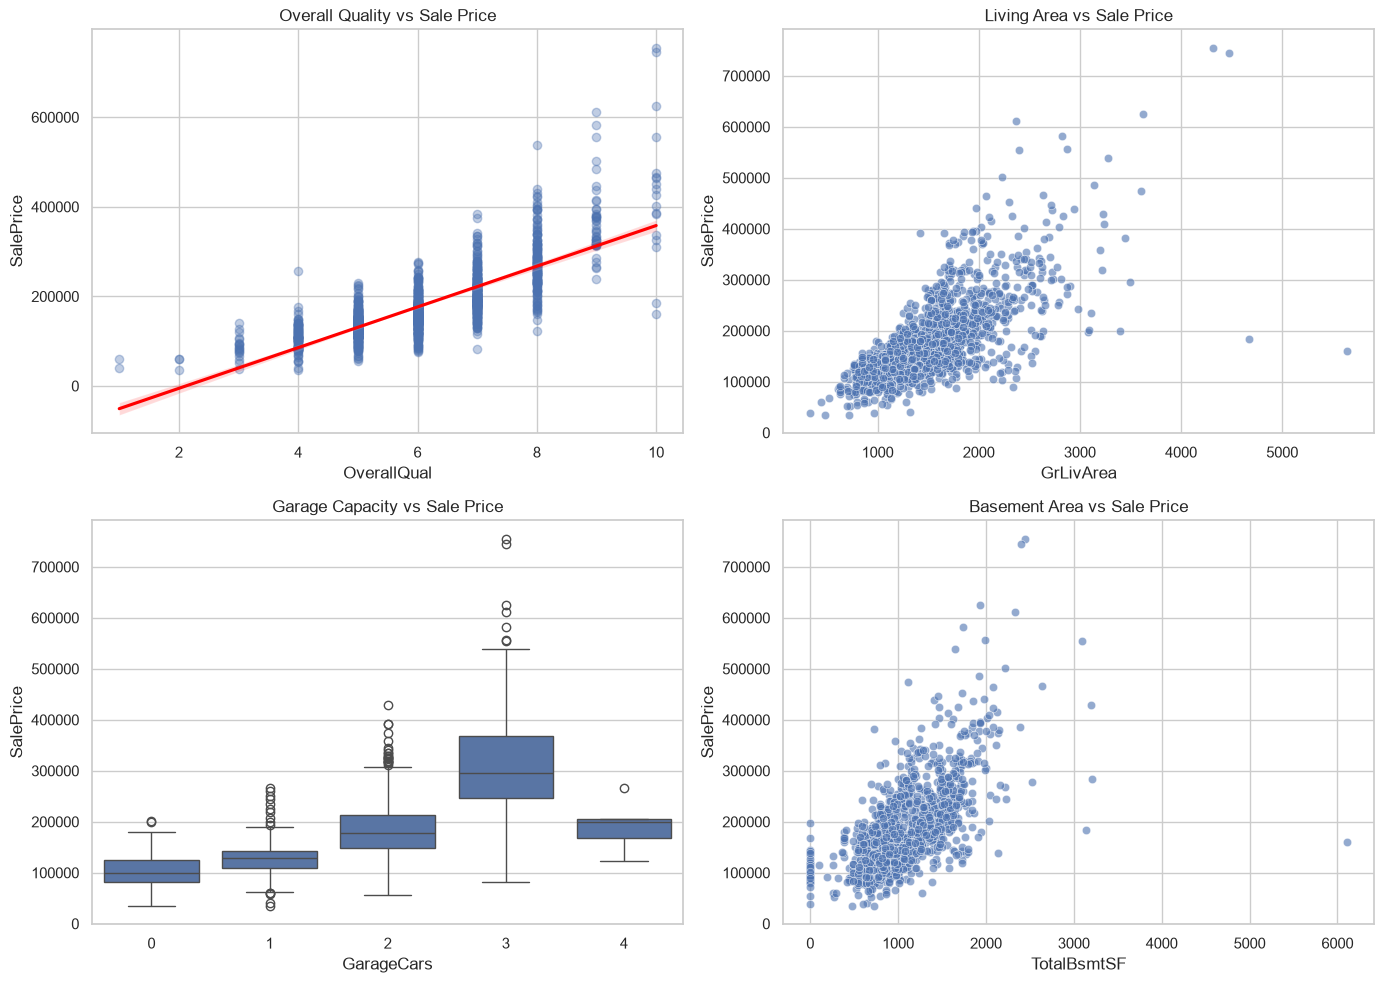

In [54]:

# Check the selected columns are available
features = [
    "OverallQual",
    "GrLivArea",
    "GarageCars",
    "TotalBsmtSF"
]

print("Selected feature summaries:")
display(df[features + ["SalePrice"]].describe().round(2))

# Relationship between overall quality and sale price
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.regplot(
    data=df, x="OverallQual", y="SalePrice",
    scatter_kws={"alpha": 0.35},
    line_kws={"color": "red"},
    ax=axes[0, 0]
)
axes[0, 0].set_title("Overall Quality vs Sale Price")

sns.scatterplot(
    data=df, x="GrLivArea", y="SalePrice",
    alpha=0.6, ax=axes[0, 1]
)
axes[0, 1].set_title("Living Area vs Sale Price")

sns.boxplot(
    data=df, x="GarageCars", y="SalePrice",
    ax=axes[1, 0]
)
axes[1, 0].set_title("Garage Capacity vs Sale Price")

sns.scatterplot(
    data=df, x="TotalBsmtSF", y="SalePrice",
    alpha=0.6, ax=axes[1, 1]
)
axes[1, 1].set_title("Basement Area vs Sale Price")

plt.tight_layout()
plt.show()


Top 15 positively correlated features:


,Correlation with SalePrice
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897
YearRemodAdd,0.507101



Top 15 negatively correlated features:


,Correlation with SalePrice
KitchenAbvGr,-0.135907
EnclosedPorch,-0.128578
MSSubClass,-0.084284
OverallCond,-0.077856
YrSold,-0.028923
LowQualFinSF,-0.025606
Id,-0.021917
MiscVal,-0.021190
BsmtHalfBath,-0.016844
BsmtFinSF2,-0.011378


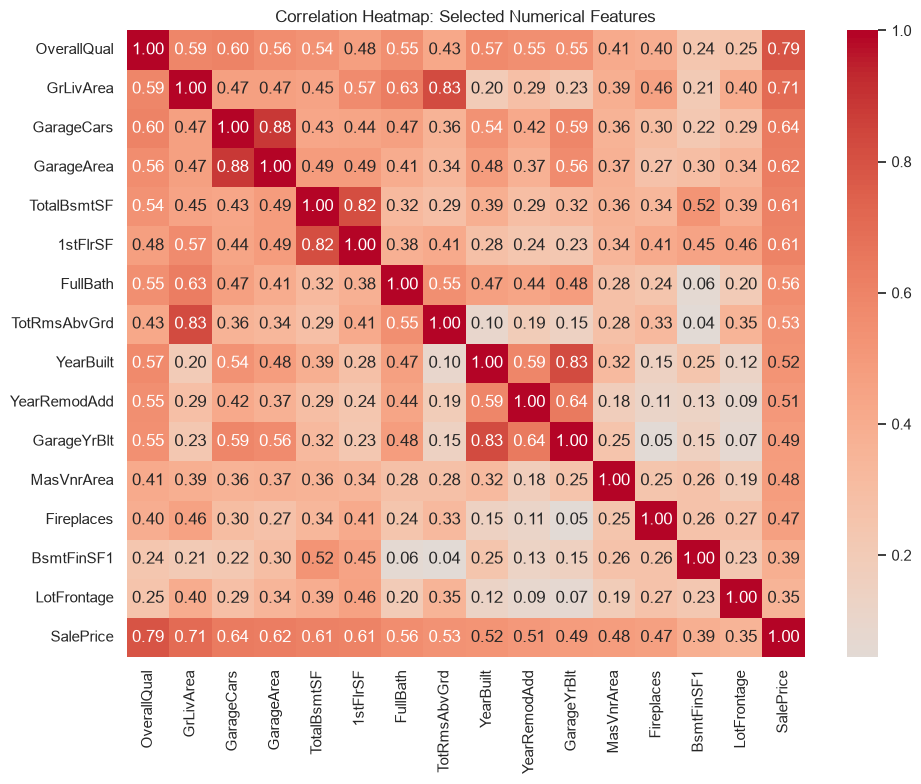

In [55]:

# STEP 15: NUMERICAL FEATURE CORRELATION ANALYSIS

numeric_df = df.select_dtypes(include="number")

# Calculate correlation with the target
price_corr = (
    numeric_df.corr()["SalePrice"]
    .drop("SalePrice")
    .sort_values(ascending=False)
)

print("Top 15 positively correlated features:")
display(price_corr.head(15).to_frame("Correlation with SalePrice"))

print("\nTop 15 negatively correlated features:")
display(price_corr.tail(15).sort_values().to_frame(
    "Correlation with SalePrice"
))

# Visualize the strongest positive and negative relationships
top_features = price_corr.abs().nlargest(15).index

plt.figure(figsize=(10, 8))
sns.heatmap(
    df[list(top_features) + ["SalePrice"]]
    .select_dtypes(include="number")
    .corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Heatmap: Selected Numerical Features")
plt.tight_layout()
plt.show()


In [56]:

missing_audit = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": df.isnull().mean() * 100
})

missing_audit = (
    missing_audit[missing_audit["Missing_Count"] > 0]
    .sort_values("Missing_Percentage", ascending=False)
)

display(missing_audit.round(2))


,Missing_Count,Missing_Percentage
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55



### Missing-Value Analysis

The dataset contains missing values in 19 columns. Missingness is particularly high in PoolQC (99.52%), MiscFeature (96.30%), Alley (93.77%), and Fence (80.75%). Several garage and basement features have smaller amounts of missing data, while Electrical and MasVnrArea have very few missing observations.

These missing values will not be handled by deleting all affected rows, because doing so could remove a substantial amount of useful information. Instead, the meaning of missingness will be examined. For categorical property features, missing values may indicate that a feature is absent; this interpretation must be verified against the dataset's feature definitions. Remaining missing values will be handled within a preprocessing pipeline to avoid data leakage.


In [57]:

# Compare house prices for rows with and without missing values
columns_to_check = [
    "PoolQC", "MiscFeature", "Alley", "Fence",
    "MasVnrType", "FireplaceQu", "LotFrontage",
    "GarageType", "Electrical"
]

missing_price_summary = []

for col in columns_to_check:
    missing_mask = df[col].isna()

    missing_price_summary.append({
        "Feature": col,
        "Missing_Rows": int(missing_mask.sum()),
        "Missing_Median_SalePrice": (
            df.loc[missing_mask, "SalePrice"].median()
            if missing_mask.sum() > 0 else None
        ),
        "NonMissing_Median_SalePrice": (
            df.loc[~missing_mask, "SalePrice"].median()
        )
    })

missing_price_summary = pd.DataFrame(missing_price_summary)
display(missing_price_summary.round(2))


,Feature,Missing_Rows,Missing_Median_SalePrice,NonMissing_Median_SalePrice
0,PoolQC,1453,162900.0,235000.0
1,MiscFeature,1406,164250.0,146000.0
2,Alley,1369,165000.0,140000.0
3,Fence,1179,173000.0,141500.0
4,MasVnrType,872,143125.0,192250.0
5,FireplaceQu,690,135000.0,191000.0
6,LotFrontage,259,172400.0,159500.0
7,GarageType,81,100000.0,167500.0
8,Electrical,1,167500.0,163000.0



### Investigating Missing Values and Sale Price

A comparison of median sale prices for records with missing and non-missing feature values showed differences across several property features.

- **PoolQC:** Missing records have a median sale price of $162,900, compared with $235,000 for non-missing records.
- **FireplaceQu:** Missing records have a median of $135,000, compared with $191,000 for non-missing records.
- **MasVnrType:** Missing records have a median of $143,125, compared with $192,250 for non-missing records.
- **GarageType:** Missing records have a median of $100,000, compared with $167,500 for non-missing records.
- **LotFrontage:** Missing records have a median of $172,400, compared with $159,500 for non-missing records.

These differences suggest that missingness may contain useful information about property characteristics. However, the comparison is descriptive and does not establish causation. Missing values will be handled according to feature meaning, with preprocessing fitted only on training data.


Top 15 positively correlated features:


,Correlation with SalePrice
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897
YearRemodAdd,0.507101



Top 15 negatively correlated features:


,Correlation with SalePrice
KitchenAbvGr,-0.135907
EnclosedPorch,-0.128578
MSSubClass,-0.084284
OverallCond,-0.077856
YrSold,-0.028923
LowQualFinSF,-0.025606
Id,-0.021917
MiscVal,-0.021190
BsmtHalfBath,-0.016844
BsmtFinSF2,-0.011378


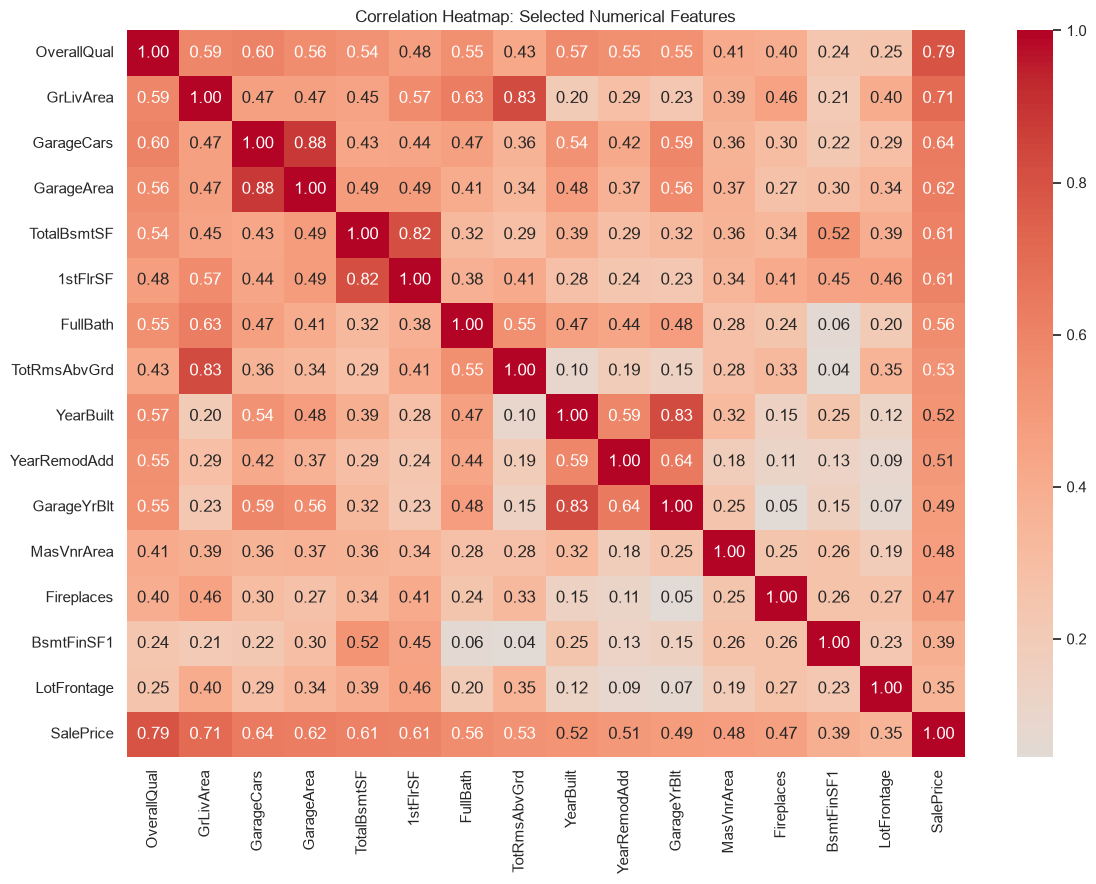

In [58]:

# Correlation of numerical features with SalePrice
numeric_df = df.select_dtypes(include="number")

price_corr = (
    numeric_df.corr()["SalePrice"]
    .drop("SalePrice")
    .sort_values(ascending=False)
)

print("Top 15 positively correlated features:")
display(price_corr.head(15).to_frame("Correlation with SalePrice"))

print("\nTop 15 negatively correlated features:")
display(
    price_corr.tail(15)
    .sort_values()
    .to_frame("Correlation with SalePrice")
)

# Heatmap of the 15 numerical features most strongly correlated with price
top_features = price_corr.abs().nlargest(15).index.tolist()

plt.figure(figsize=(12, 9))
sns.heatmap(
    df[top_features + ["SalePrice"]]
    .select_dtypes(include="number")
    .corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Heatmap: Selected Numerical Features")
plt.tight_layout()
plt.show()


Top 15 positively correlated features:


,Correlation with SalePrice
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897
YearRemodAdd,0.507101



Top 15 negatively correlated features:


,Correlation with SalePrice
KitchenAbvGr,-0.135907
EnclosedPorch,-0.128578
MSSubClass,-0.084284
OverallCond,-0.077856
YrSold,-0.028923
LowQualFinSF,-0.025606
Id,-0.021917
MiscVal,-0.021190
BsmtHalfBath,-0.016844
BsmtFinSF2,-0.011378


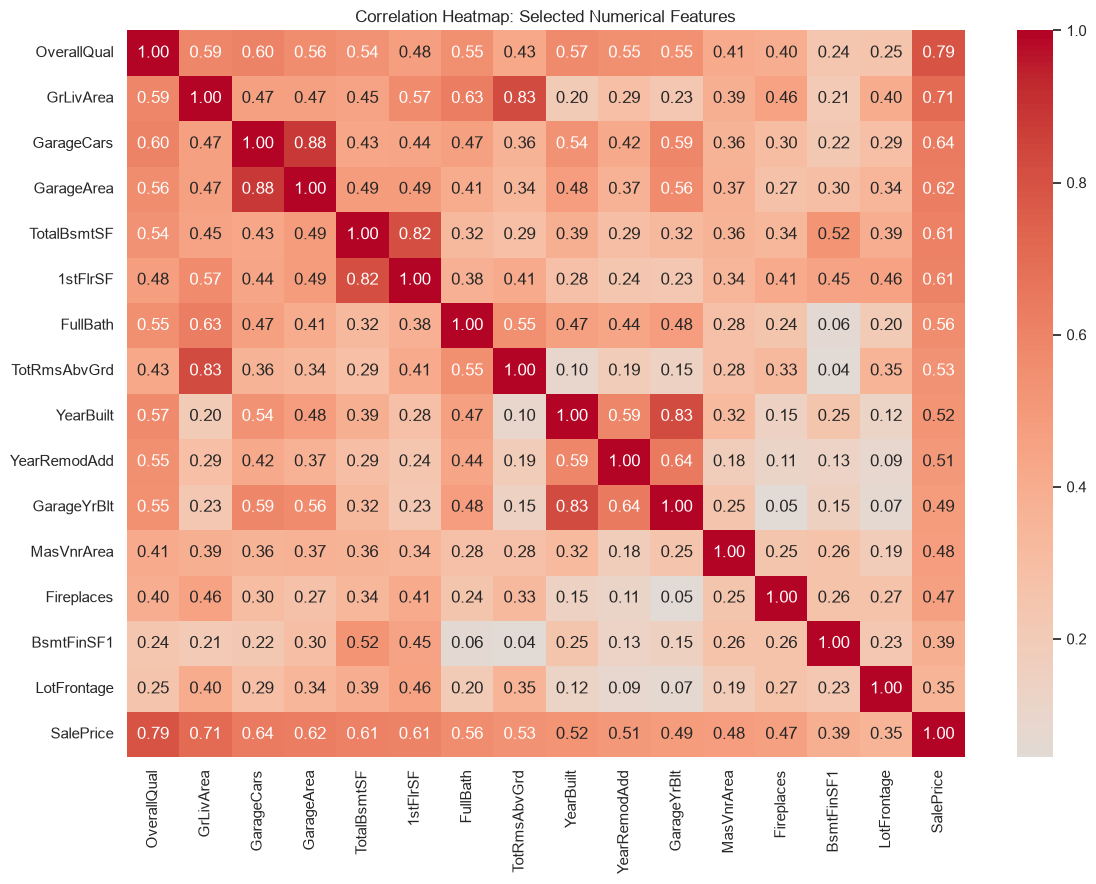

In [59]:

# Step 20: Correlation Analysis

numeric_df = df.select_dtypes(include="number")

price_corr = (
    numeric_df.corr()["SalePrice"]
    .drop("SalePrice")
    .sort_values(ascending=False)
)

print("Top 15 positively correlated features:")
display(price_corr.head(15).to_frame("Correlation with SalePrice"))

print("\nTop 15 negatively correlated features:")
display(
    price_corr.tail(15)
    .sort_values()
    .to_frame("Correlation with SalePrice")
)

# Visualize the strongest numerical relationships
top_features = price_corr.abs().nlargest(15).index.tolist()

plt.figure(figsize=(12, 9))
sns.heatmap(
    df[top_features + ["SalePrice"]]
    .select_dtypes(include="number")
    .corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap: Selected Numerical Features")
plt.tight_layout()
plt.show()


# Check the target and prepare features
Before building models, we should separate the target (SalePrice) from the input features and check the dataset for possible leakage or identifiers.

In [60]:

# Step 23: Prepare target and inspect feature types

target = "SalePrice"

X = df.drop(columns=[target]).copy()
y = df[target].copy()

print("Dataset shape:", df.shape)
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget missing values:", y.isna().sum())
print("Target data type:", y.dtype)

print("\nIdentifier-like columns:")
print([col for col in X.columns if col.lower() in ["id", "idnumber", "empnumber"]])

print("\nNumerical features:", X.select_dtypes(include="number").shape[1])
print("Categorical features:", X.select_dtypes(exclude="number").shape[1])

print("\nTarget summary:")
display(y.describe().to_frame("SalePrice"))


Dataset shape: (1460, 81)
Feature matrix shape: (1460, 80)
Target shape: (1460,)

Target missing values: 0
Target data type: int64

Identifier-like columns:
['Id']

Numerical features: 37
Categorical features: 43

Target summary:


,SalePrice
count,1460.000000
mean,180921.195890
std,79442.502883
min,34900.000000
25%,129975.000000
50%,163000.000000
75%,214000.000000
max,755000.000000


In [61]:

# Step 24: Train-Test Split

from sklearn.model_selection import train_test_split

# Remove Id because it is an identifier, not a meaningful house characteristic
X = df.drop(columns=["SalePrice", "Id"]).copy()
y = df["SalePrice"].copy()

# Split before fitting any preprocessing or machine-learning model
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

print("\nTraining set percentage:", round(len(X_train) / len(df) * 100, 2), "%")
print("Testing set percentage:", round(len(X_test) / len(df) * 100, 2), "%")

print("\nMissing values in training target:", y_train.isna().sum())
print("Missing values in testing target:", y_test.isna().sum())


Training features shape: (1168, 79)
Testing features shape: (292, 79)
Training target shape: (1168,)
Testing target shape: (292,)

Training set percentage: 80.0 %
Testing set percentage: 20.0 %

Missing values in training target: 0
Missing values in testing target: 0


# Build a preprocessing pipeline
Your dataset has both numerical and categorical features, plus missing values. Machine-learning models need these handled properly. We'll use a scikit-learn pipeline so the imputers and encoders are fitted only on the training data, preventing data leakage.

In [62]:

# Step 25: Create a Leakage-Safe Preprocessing Pipeline

import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify numerical and categorical columns from the training set
numeric_features = X_train.select_dtypes(include="number").columns.tolist()
categorical_features = X_train.select_dtypes(exclude="number").columns.tolist()

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

# Numerical preprocessing: median imputation
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing: most-frequent imputation + one-hot encoding
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Apply the appropriate preprocessing to each feature type
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("\nPreprocessing pipeline created successfully.")
print("Numerical strategy: median imputation")
print("Categorical strategy: most-frequent imputation + one-hot encoding")


Numerical features: 36
Categorical features: 43

Preprocessing pipeline created successfully.
Numerical strategy: median imputation
Categorical strategy: most-frequent imputation + one-hot encoding


In [63]:

# Step 26: Train Baseline Regression Models

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import pandas as pd
import numpy as np
import time

# Define the two required models
models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

trained_models = {}
results = []

for model_name, regressor in models.items():
    print(f"Training {model_name}...")

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", regressor)
    ])

    start_time = time.time()
    pipeline.fit(X_train, y_train)
    training_time = time.time() - start_time

    # Predict on the untouched test set
    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    trained_models[model_name] = pipeline

    results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2_Score": r2,
        "Training_Time_Seconds": training_time
    })

baseline_results = pd.DataFrame(results).sort_values("RMSE")

print("\nBaseline Model Comparison:")
display(baseline_results.round(3))


Training Random Forest...
Training Gradient Boosting...

Baseline Model Comparison:


,Model,MAE,RMSE,R2_Score,Training_Time_Seconds
1,Gradient Boosting,16570.520,26577.074,0.908,3.083
0,Random Forest,17386.106,28495.231,0.894,8.830



### Baseline Model Comparison

Two regression algorithms were evaluated using the same training and test split and the same preprocessing pipeline.

Gradient Boosting achieved a test MAE of $16,570.52, RMSE of $26,577.07, and R² of 0.908. Random Forest achieved a test MAE of $17,386.11, RMSE of $28,495.23, and R² of 0.894.

Gradient Boosting outperformed Random Forest on all three evaluation metrics in this baseline experiment and also had a shorter recorded training time. However, these results represent initial configurations only. Hyperparameter tuning and further validation are required before selecting the final model.


In [64]:

# Step 29: Hyperparameter Tuning with Cross-Validation

from sklearn.model_selection import RandomizedSearchCV

# Random Forest pipeline
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(random_state=42, n_jobs=1))
])

rf_params = {
    "model__n_estimators": [150, 200, 300],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": [0.7, 1.0]
}

# Gradient Boosting pipeline
gb_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", GradientBoostingRegressor(random_state=42))
])

gb_params = {
    "model__n_estimators": [100, 150, 200],
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__max_depth": [2, 3],
    "model__subsample": [0.8, 1.0]
}

search_spaces = {
    "Random Forest": (rf_pipeline, rf_params),
    "Gradient Boosting": (gb_pipeline, gb_params)
}

tuned_models = {}
tuning_results = []

for name, (pipeline, params) in search_spaces.items():
    print(f"\nTuning {name}...")

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=params,
        n_iter=8,
        scoring="neg_root_mean_squared_error",
        cv=3,
        random_state=42,
        n_jobs=-1,
        verbose=1,
        return_train_score=True
    )

    search.fit(X_train, y_train)

    tuned_models[name] = search.best_estimator_

    tuning_results.append({
        "Model": name,
        "Best_CV_RMSE": -search.best_score_,
        "Best_Parameters": search.best_params_
    })

    print("Best cross-validation RMSE:", round(-search.best_score_, 2))
    print("Best parameters:", search.best_params_)

tuning_summary = pd.DataFrame(tuning_results)
print("\nHyperparameter Tuning Summary:")
display(tuning_summary)



Tuning Random Forest...
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best cross-validation RMSE: 29153.95
Best parameters: {'model__n_estimators': 300, 'model__min_samples_leaf': 2, 'model__max_features': 0.7, 'model__max_depth': None}

Tuning Gradient Boosting...
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best cross-validation RMSE: 26337.5
Best parameters: {'model__subsample': 0.8, 'model__n_estimators': 100, 'model__max_depth': 3, 'model__learning_rate': 0.1}

Hyperparameter Tuning Summary:


,Model,Best_CV_RMSE,Best_Parameters
0,Random Forest,29153.947722,"{'model__n_estimators': 300, 'model__min_sampl..."
1,Gradient Boosting,26337.503821,"{'model__subsample': 0.8, 'model__n_estimators..."


In [65]:

# Step 30: Evaluate Tuned Models on the Untouched Test Set

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

tuned_test_results = []
tuned_predictions = {}

for name, model in tuned_models.items():
    predictions = model.predict(X_test)
    tuned_predictions[name] = predictions

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    tuned_test_results.append({
        "Model": name,
        "Test_MAE": mae,
        "Test_RMSE": rmse,
        "Test_R2": r2
    })

tuned_test_results = (
    pd.DataFrame(tuned_test_results)
    .sort_values("Test_RMSE")
    .reset_index(drop=True)
)

display(tuned_test_results.round(3))


,Model,Test_MAE,Test_RMSE,Test_R2
0,Gradient Boosting,16631.389,27400.002,0.902
1,Random Forest,17365.526,28881.743,0.891


Prediction error summary:


,Residual,Absolute_Error
count,292.00,292.00
mean,336.40,16570.52
std,26620.57,20814.48
min,-127435.22,76.14
25%,-11709.22,4645.06
50%,298.09,11542.00
75%,11157.66,21574.73
max,191238.43,191238.43


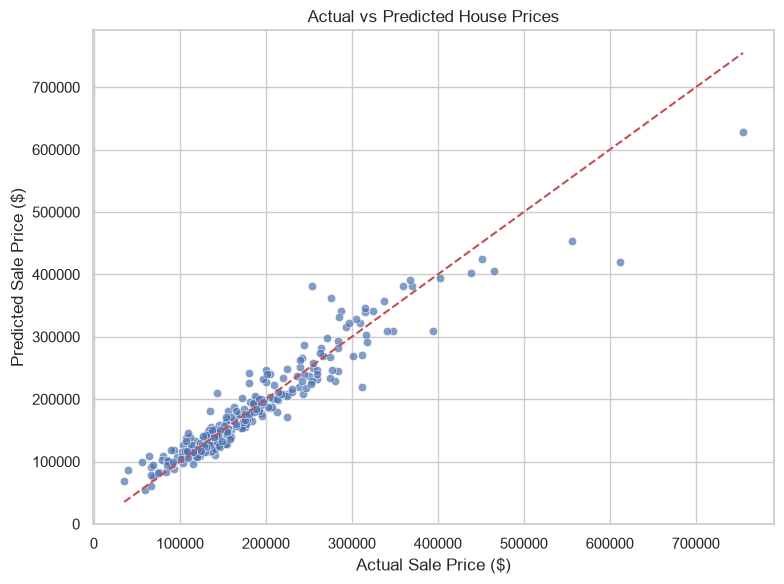

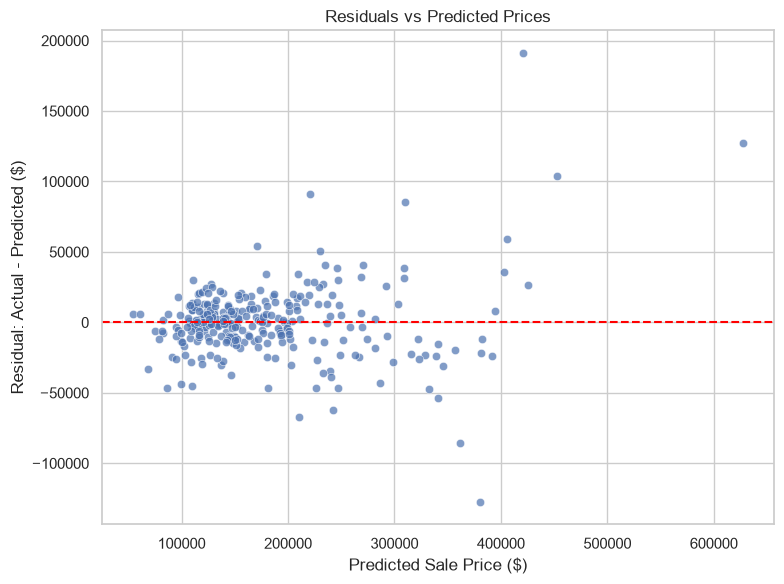

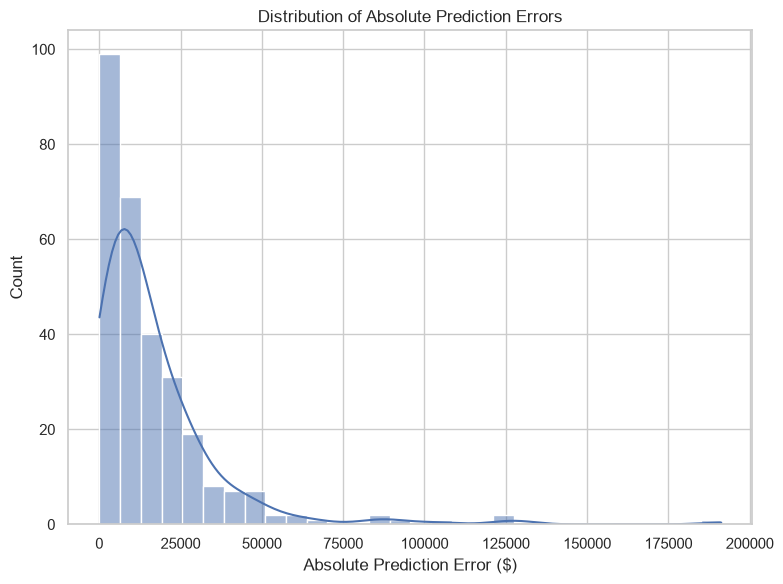

In [66]:

# Step 32: Prediction Error Analysis for Baseline Gradient Boosting

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

best_baseline_model = trained_models["Gradient Boosting"]

baseline_predictions = best_baseline_model.predict(X_test)

residuals = y_test.to_numpy() - baseline_predictions

error_df = pd.DataFrame({
    "Actual_Price": y_test.to_numpy(),
    "Predicted_Price": baseline_predictions,
    "Residual": residuals,
    "Absolute_Error": np.abs(residuals)
})

print("Prediction error summary:")
display(error_df[["Residual", "Absolute_Error"]].describe().round(2))

# Plot 1: Actual vs predicted prices
plt.figure(figsize=(8, 6))
sns.scatterplot(
    x=error_df["Actual_Price"],
    y=error_df["Predicted_Price"],
    alpha=0.7
)

min_price = min(error_df["Actual_Price"].min(),
                error_df["Predicted_Price"].min())
max_price = max(error_df["Actual_Price"].max(),
                error_df["Predicted_Price"].max())

plt.plot([min_price, max_price], [min_price, max_price], "r--")
plt.xlabel("Actual Sale Price ($)")
plt.ylabel("Predicted Sale Price ($)")
plt.title("Actual vs Predicted House Prices")
plt.tight_layout()
plt.show()

# Plot 2: Residuals vs predicted prices
plt.figure(figsize=(8, 6))
sns.scatterplot(
    x=error_df["Predicted_Price"],
    y=error_df["Residual"],
    alpha=0.7
)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted Sale Price ($)")
plt.ylabel("Residual: Actual - Predicted ($)")
plt.title("Residuals vs Predicted Prices")
plt.tight_layout()
plt.show()

# Plot 3: Distribution of absolute errors
plt.figure(figsize=(8, 6))
sns.histplot(error_df["Absolute_Error"], bins=30, kde=True)
plt.xlabel("Absolute Prediction Error ($)")
plt.title("Distribution of Absolute Prediction Errors")
plt.tight_layout()
plt.show()


,Actual_Price,Predicted_Price,Residual,Absolute_Error
74,611657,420418.57,191238.43,191238.43
43,253293,380728.22,-127435.22,127435.22
139,755000,627831.19,127168.81,127168.81
168,556581,452918.36,103662.64,103662.64
6,311500,220202.10,91297.90,91297.90
260,395000,309447.89,85552.11,85552.11
167,276000,361533.62,-85533.62,85533.62
278,143000,210271.54,-67271.54,67271.54
271,180000,242453.97,-62453.97,62453.97
270,465000,405555.30,59444.70,59444.70


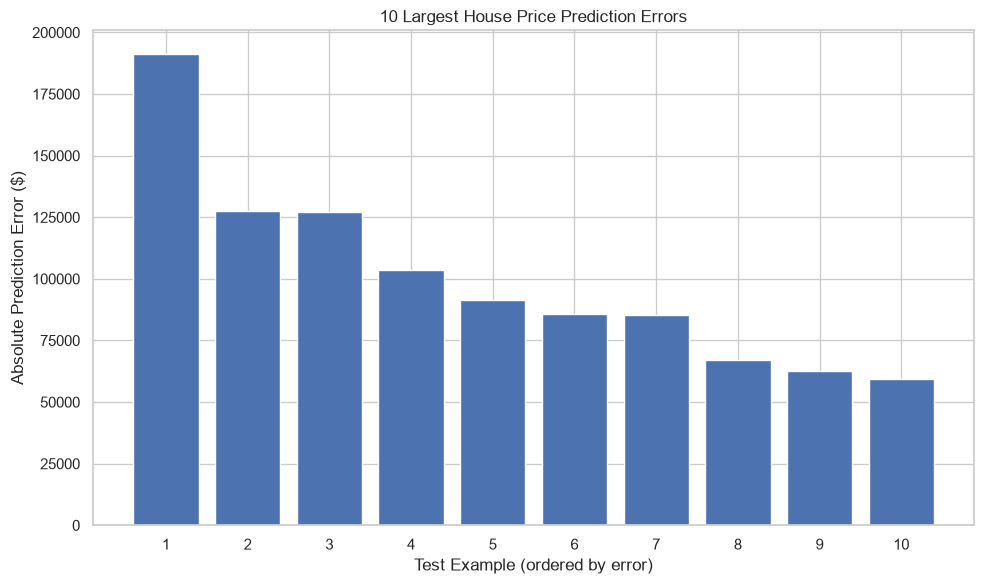

In [67]:

# Step 34: Inspect the 10 Largest Prediction Errors

largest_errors = (
    error_df
    .sort_values("Absolute_Error", ascending=False)
    .head(10)
    .copy()
)

display(largest_errors.round(2))

# Compare the actual and predicted prices for these examples
plt.figure(figsize=(10, 6))

error_plot_df = largest_errors.reset_index(drop=True)

plt.bar(
    range(1, len(error_plot_df) + 1),
    error_plot_df["Absolute_Error"]
)

plt.xlabel("Test Example (ordered by error)")
plt.ylabel("Absolute Prediction Error ($)")
plt.title("10 Largest House Price Prediction Errors")
plt.xticks(range(1, len(error_plot_df) + 1))
plt.tight_layout()
plt.show()


In [68]:

# Step 36: Inspect House Characteristics for the Largest Errors

# Keep the original test-set row positions for matching features
largest_errors = error_df.sort_values(
    "Absolute_Error", ascending=False
).head(10)

# Match the error rows to the corresponding test features
top_error_features = X_test.iloc[largest_errors.index].copy()

top_error_analysis = top_error_features.copy()
top_error_analysis["Actual_Price"] = largest_errors["Actual_Price"].to_numpy()
top_error_analysis["Predicted_Price"] = largest_errors["Predicted_Price"].to_numpy()
top_error_analysis["Absolute_Error"] = largest_errors["Absolute_Error"].to_numpy()

# Display selected interpretable features if available
features_to_show = [
    "OverallQual",
    "GrLivArea",
    "GarageCars",
    "GarageArea",
    "TotalBsmtSF",
    "YearBuilt",
    "Neighborhood",
    "HouseStyle"
]

available_features = [
    col for col in features_to_show
    if col in top_error_analysis.columns
]

display(
    top_error_analysis[
        available_features + [
            "Actual_Price",
            "Predicted_Price",
            "Absolute_Error"
        ]
    ].round(2)
)


,OverallQual,GrLivArea,GarageCars,GarageArea,TotalBsmtSF,YearBuilt,Neighborhood,HouseStyle,Actual_Price,Predicted_Price,Absolute_Error
898,9,2364,3,820,2330,2009,NridgHt,1Story,611657,420418.57,191238.43
581,8,2042,3,1390,2042,2008,NridgHt,1Story,253293,380728.22,127435.22
691,10,4316,3,832,2444,1994,NoRidge,2Story,755000,627831.19,127168.81
1046,9,2868,3,716,1992,2005,StoneBr,2Story,556581,452918.36,103662.64
218,7,1954,2,431,798,1939,Crawfor,1.5Fin,311500,220202.10,91297.90
774,8,1973,3,895,1935,2006,NridgHt,1Story,395000,309447.89,85552.11
261,8,2574,3,868,1482,2007,CollgCr,2Story,276000,361533.62,85533.62
588,5,1473,1,452,1437,1968,ClearCr,1Story,143000,210271.54,67271.54
744,8,1337,2,462,1337,1993,StoneBr,1Story,180000,242453.97,62453.97
1243,10,2076,3,850,2076,2006,NridgHt,1Story,465000,405555.30,59444.70


# Inspect the 10 largest prediction errors 

In [69]:

largest_errors = error_df.sort_values(
    "Absolute_Error", ascending=False
).head(10)

top_error_features = X_test.iloc[largest_errors.index].copy()

top_error_analysis = top_error_features.copy()
top_error_analysis["Actual_Price"] = largest_errors["Actual_Price"].to_numpy()
top_error_analysis["Predicted_Price"] = largest_errors["Predicted_Price"].to_numpy()
top_error_analysis["Absolute_Error"] = largest_errors["Absolute_Error"].to_numpy()

features_to_show = [
    "OverallQual", "GrLivArea", "GarageCars", "GarageArea",
    "TotalBsmtSF", "YearBuilt", "Neighborhood", "HouseStyle"
]

available_features = [
    col for col in features_to_show
    if col in top_error_analysis.columns
]

display(
    top_error_analysis[
        available_features
        + ["Actual_Price", "Predicted_Price", "Absolute_Error"]
    ].round(2)
)


,OverallQual,GrLivArea,GarageCars,GarageArea,TotalBsmtSF,YearBuilt,Neighborhood,HouseStyle,Actual_Price,Predicted_Price,Absolute_Error
898,9,2364,3,820,2330,2009,NridgHt,1Story,611657,420418.57,191238.43
581,8,2042,3,1390,2042,2008,NridgHt,1Story,253293,380728.22,127435.22
691,10,4316,3,832,2444,1994,NoRidge,2Story,755000,627831.19,127168.81
1046,9,2868,3,716,1992,2005,StoneBr,2Story,556581,452918.36,103662.64
218,7,1954,2,431,798,1939,Crawfor,1.5Fin,311500,220202.10,91297.90
774,8,1973,3,895,1935,2006,NridgHt,1Story,395000,309447.89,85552.11
261,8,2574,3,868,1482,2007,CollgCr,2Story,276000,361533.62,85533.62
588,5,1473,1,452,1437,1968,ClearCr,1Story,143000,210271.54,67271.54
744,8,1337,2,462,1337,1993,StoneBr,1Story,180000,242453.97,62453.97
1243,10,2076,3,850,2076,2006,NridgHt,1Story,465000,405555.30,59444.70


In [70]:

best_baseline_model = trained_models["Gradient Boosting"]

fitted_preprocessor = best_baseline_model.named_steps["preprocessor"]
gb_regressor = best_baseline_model.named_steps["model"]

feature_names = fitted_preprocessor.get_feature_names_out()
importances = gb_regressor.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

display(feature_importance.head(20))


,Feature,Importance
3,num__OverallQual,0.513633
15,num__GrLivArea,0.142408
25,num__GarageCars,0.044162
11,num__TotalBsmtSF,0.042850
8,num__BsmtFinSF1,0.030665
13,num__2ndFlrSF,0.029224
12,num__1stFlrSF,0.026761
2,num__LotArea,0.018031
245,cat__GarageFinish_Unf,0.016698
180,cat__BsmtQual_Ex,0.014974


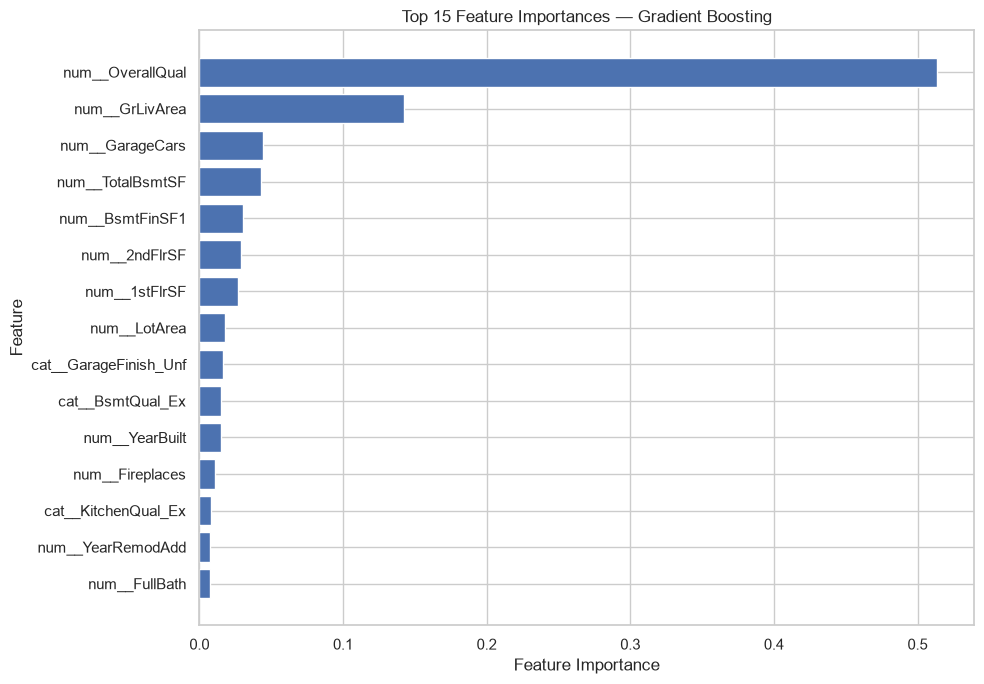

In [71]:

top_features = feature_importance.head(15).sort_values(
    "Importance", ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 15 Feature Importances — Gradient Boosting")
plt.tight_layout()
plt.show()



### Feature Importance Analysis

Feature importance helps identify which input variables the Gradient Boosting model relies on most when predicting house sale prices.

The top features will be reviewed to understand the contribution of property quality, living area, location, and other house characteristics to the model's predictions.

**Interpretation note:** Feature importance indicates how useful a feature was to this fitted model. It does not prove that the feature causes a change in house prices, and it does not indicate whether the relationship is positive or negative.


In [72]:

def add_house_features(data):
    data = data.copy()

    # Total usable area across major house levels
    data["TotalSF"] = (
        data["TotalBsmtSF"].fillna(0)
        + data["1stFlrSF"].fillna(0)
        + data["2ndFlrSF"].fillna(0)
    )

    # Total bathrooms, including half bathrooms
    data["TotalBathrooms"] = (
        data["FullBath"].fillna(0)
        + 0.5 * data["HalfBath"].fillna(0)
        + data["BsmtFullBath"].fillna(0)
        + 0.5 * data["BsmtHalfBath"].fillna(0)
    )

    # Total porch area
    porch_columns = [
        "OpenPorchSF", "EnclosedPorch",
        "3SsnPorch", "ScreenPorch", "WoodDeckSF"
    ]
    data["TotalPorchSF"] = data[porch_columns].fillna(0).sum(axis=1)

    return data


X_train_fe = add_house_features(X_train)
X_test_fe = add_house_features(X_test)

print("Original training features:", X_train.shape[1])
print("Engineered training features:", X_train_fe.shape[1])
print("Original test features:", X_test.shape[1])
print("Engineered test features:", X_test_fe.shape[1])

display(X_train_fe[["TotalSF", "TotalBathrooms", "TotalPorchSF"]].head())


Original training features: 79
Engineered training features: 82
Original test features: 79
Engineered test features: 82


,TotalSF,TotalBathrooms,TotalPorchSF
254,2628,2.0,250
1066,2370,2.5,40
638,1592,1.0,492
799,2499,2.5,264
380,2717,2.0,242


In [73]:

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd

# Identify feature types again, including the 3 new features
numeric_features_fe = X_train_fe.select_dtypes(
    include="number"
).columns.tolist()

categorical_features_fe = X_train_fe.select_dtypes(
    exclude="number"
).columns.tolist()

# Build preprocessing specifically for the engineered dataset
preprocessor_fe = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_features_fe),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features_fe)
])

# Train Gradient Boosting using the same baseline settings
engineered_gb_model = Pipeline([
    ("preprocessor", preprocessor_fe),
    ("model", GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

engineered_gb_model.fit(X_train_fe, y_train)
engineered_predictions = engineered_gb_model.predict(X_test_fe)

# Evaluate the original and engineered versions
original_model = trained_models["Gradient Boosting"]
original_predictions = original_model.predict(X_test)

comparison = pd.DataFrame([
    {
        "Model": "Gradient Boosting - Original Features",
        "MAE": mean_absolute_error(y_test, original_predictions),
        "RMSE": mean_squared_error(y_test, original_predictions) ** 0.5,
        "R2": r2_score(y_test, original_predictions)
    },
    {
        "Model": "Gradient Boosting - Engineered Features",
        "MAE": mean_absolute_error(y_test, engineered_predictions),
        "RMSE": mean_squared_error(y_test, engineered_predictions) ** 0.5,
        "R2": r2_score(y_test, engineered_predictions)
    }
])

display(comparison.round(3))


,Model,MAE,RMSE,R2
0,Gradient Boosting - Original Features,16570.520,26577.074,0.908
1,Gradient Boosting - Engineered Features,16190.894,26669.746,0.907



### Feature Engineering and Model Comparison

Three features were engineered: TotalSF, TotalBathrooms, and TotalPorchSF.

The engineered Gradient Boosting model achieved an MAE of 16,190.89, compared with 16,570.52 for the original model. However, its RMSE increased from 26,577.07 to 26,669.75, while R² decreased from 0.908 to 0.907.

The engineered model therefore reduced average absolute error slightly but did not improve all evaluation metrics. The original-feature Gradient Boosting model remains the leading candidate based on RMSE and R².

These results are exploratory because the test set has been used for repeated model comparisons.


# Compare Random Forest and Gradient Boosting using cross-validation
This is important because cross-validation helps us assess model performance across multiple training/validation splits, rather than relying only on one test split.

In [74]:

from sklearn.model_selection import cross_validate, KFold
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.pipeline import Pipeline
import pandas as pd
import numpy as np

cv = KFold(n_splits=5, shuffle=True, random_state=42)

models_for_cv = {
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

cv_results = []

for name, model in models_for_cv.items():
    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", model)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2"
        },
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Mean MAE": -scores["test_mae"].mean(),
        "Mean RMSE": -scores["test_rmse"].mean(),
        "Mean R2": scores["test_r2"].mean(),
        "RMSE Std": scores["test_rmse"].std()
    })

cv_comparison = pd.DataFrame(cv_results)
display(cv_comparison.round(3))


,Model,Mean MAE,Mean RMSE,Mean R2,RMSE Std
0,Random Forest,18162.786,30168.271,0.845,4933.874
1,Gradient Boosting,16140.975,27900.411,0.865,6321.980



### Cross-Validation Model Comparison

Five-fold cross-validation was performed on the training dataset using the same folds for Random Forest and Gradient Boosting.

Gradient Boosting achieved a mean MAE of 16,140.98, mean RMSE of 27,900.41, and mean R² of 0.865. Random Forest achieved a mean MAE of 18,162.79, mean RMSE of 30,168.27, and mean R² of 0.845.

Gradient Boosting performed better on the mean error and R² metrics. Random Forest had a lower RMSE standard deviation (4,933.87 compared with 6,321.98), indicating less variation in RMSE across these folds.

Based on these results, Gradient Boosting is the leading baseline candidate. The final choice should also consider the held-out test results, prediction errors, and model limitations.



## Final Model Evaluation and Recommendation

### Models Evaluated

Random Forest and Gradient Boosting were evaluated using a baseline comparison, hyperparameter tuning, and five-fold cross-validation. Additional engineered features were also tested with Gradient Boosting.

### Model Recommendation

Gradient Boosting is the leading candidate based on the current results.

In five-fold cross-validation, it achieved a mean MAE of 16,140.98, mean RMSE of 27,900.41, and mean R² of 0.865. The original-feature Gradient Boosting model achieved a test MAE of 16,570.52, RMSE of 26,577.07, and R² of 0.908.

The engineered-feature model reduced MAE slightly but did not improve RMSE or R². Therefore, the original-feature Gradient Boosting model remains the preferred candidate for further validation.

### Limitations

1. The dataset represents house sales in Ames, Iowa, so the results may not generalize to other housing markets.
2. Some features contain substantial missing data, and the imputation strategy may affect predictions.
3. The model makes estimates from historical data; it cannot guarantee actual selling prices.
4. Large prediction errors occurred for some houses, so individual predictions should be treated cautiously.
5. The test set was used for repeated model comparisons. Its results are therefore exploratory and should not be treated as a fully untouched final evaluation.

### Future Improvements

1. Evaluate the final model on a genuinely untouched test set or new housing data.
2. Investigate missing-value handling and additional feature engineering.
3. Compare model performance across different price ranges and neighborhoods.
4. Consider model interpretation tools and a simple prediction interface.
5. Monitor performance when new housing data becomes available.


In [75]:

import os
import joblib

# Create the models folder if it does not exist
os.makedirs("models", exist_ok=True)

# Save the recommended baseline pipeline
final_model = trained_models["Gradient Boosting"]

model_path = os.path.join("models", "house_price_gradient_boosting.joblib")
joblib.dump(final_model, model_path)

print("Model saved successfully.")
print("Saved model path:", os.path.abspath(model_path))
print("Model type:", type(final_model).__name__)


Model saved successfully.
Saved model path: C:\Users\amrut\Downloads\PRCP-1020-HousePricePred\models\house_price_gradient_boosting.joblib
Model type: Pipeline


In [76]:
# Load and test the saved model

In [77]:

import os
import joblib
import numpy as np
import pandas as pd

model_path = os.path.join(
    "models",
    "house_price_gradient_boosting.joblib"
)

loaded_model = joblib.load(model_path)

sample_houses = X_test.head(5)
sample_predictions = loaded_model.predict(sample_houses)

verification_results = pd.DataFrame({
    "Predicted_SalePrice": np.round(sample_predictions, 2)
})

print("Model loaded successfully:", type(loaded_model).__name__)
print("Number of predictions:", len(sample_predictions))

display(verification_results)


Model loaded successfully: Pipeline
Number of predictions: 5


,Predicted_SalePrice
0,145103.18
1,340633.00
2,120814.71
3,150775.19
4,339124.91


In [78]:

import os

project_root = r"C:\Users\amrut\Downloads\PRCP-1020-HousePricePred"

for root, dirs, files in os.walk(project_root):
    # Skip Jupyter's temporary checkpoint folders
    dirs[:] = [d for d in dirs if d != ".ipynb_checkpoints"]

    for file in files:
        if (
            file.endswith(".ipynb")
            or file == "data.csv"
            or file == "house_price_gradient_boosting.joblib"
        ):
            print(os.path.join(root, file))


C:\Users\amrut\Downloads\PRCP-1020-HousePricePred\PRCP-1020_House_Price_Prediction.ipynb
C:\Users\amrut\Downloads\PRCP-1020-HousePricePred\Data\data.csv
C:\Users\amrut\Downloads\PRCP-1020-HousePricePred\models\house_price_gradient_boosting.joblib


In [79]:

import os
import pandas as pd

project_root = r"C:\Users\amrut\Downloads\PRCP-1020-HousePricePred"
outputs_path = os.path.join(project_root, "outputs")
os.makedirs(outputs_path, exist_ok=True)

tables_to_save = {
    "model_comparison.csv": "comparison",
    "cross_validation_comparison.csv": "cv_comparison",
    "feature_importance.csv": "feature_importance",
    "prediction_error_analysis.csv": "error_df",
    "top_error_analysis.csv": "top_error_analysis"
}

saved_files = []

for filename, variable_name in tables_to_save.items():
    if variable_name in globals():
        table = globals()[variable_name]

        if isinstance(table, pd.DataFrame):
            file_path = os.path.join(outputs_path, filename)
            table.to_csv(file_path, index=False)
            saved_files.append(file_path)
            print("SAVED:", filename)
        else:
            print("SKIPPED (not a DataFrame):", variable_name)
    else:
        print("SKIPPED (variable not found):", variable_name)

print("\nTotal CSV files saved:", len(saved_files))
print("Output folder:", outputs_path)


SAVED: model_comparison.csv
SAVED: cross_validation_comparison.csv
SAVED: feature_importance.csv
SAVED: prediction_error_analysis.csv
SAVED: top_error_analysis.csv

Total CSV files saved: 5
Output folder: C:\Users\amrut\Downloads\PRCP-1020-HousePricePred\outputs


In [80]:

important_variables = [
    "trained_models",
    "tuned_models",
    "comparison",
    "cv_comparison",
    "feature_importance",
    "error_df",
    "top_error_analysis",
    "X_test",
    "y_test"
]

for name in important_variables:
    if name in globals():
        print(f"AVAILABLE: {name} ({type(globals()[name]).__name__})")
    else:
        print(f"NOT AVAILABLE: {name}")


AVAILABLE: trained_models (dict)
AVAILABLE: tuned_models (dict)
AVAILABLE: comparison (DataFrame)
AVAILABLE: cv_comparison (DataFrame)
AVAILABLE: feature_importance (DataFrame)
AVAILABLE: error_df (DataFrame)
AVAILABLE: top_error_analysis (DataFrame)
AVAILABLE: X_test (DataFrame)
AVAILABLE: y_test (Series)


In [81]:

import os
import pandas as pd

project_root = r"C:\Users\amrut\Downloads\PRCP-1020-HousePricePred"
outputs_path = os.path.join(project_root, "outputs")
os.makedirs(outputs_path, exist_ok=True)

tables_to_save = {
    "model_comparison.csv": comparison,
    "cross_validation_comparison.csv": cv_comparison,
    "feature_importance.csv": feature_importance,
    "prediction_error_analysis.csv": error_df,
    "top_error_analysis.csv": top_error_analysis
}

for filename, table in tables_to_save.items():
    file_path = os.path.join(outputs_path, filename)
    table.to_csv(file_path, index=False)
    print("SAVED:", filename)

print("\nFiles currently in outputs folder:")
for filename in sorted(os.listdir(outputs_path)):
    print("-", filename)


SAVED: model_comparison.csv
SAVED: cross_validation_comparison.csv
SAVED: feature_importance.csv
SAVED: prediction_error_analysis.csv
SAVED: top_error_analysis.csv

Files currently in outputs folder:
- cross_validation_comparison.csv
- feature_importance.csv
- feature_importance_xai.csv
- feature_importance_xai.png
- model_comparison.csv
- prediction_error_analysis.csv
- top_error_analysis.csv


In [82]:

import os
import matplotlib.pyplot as plt

project_root = r"C:\Users\amrut\Downloads\PRCP-1020-HousePricePred"
outputs_path = os.path.join(project_root, "outputs")
os.makedirs(outputs_path, exist_ok=True)

figure_numbers = plt.get_fignums()

print("Open figures found:", len(figure_numbers))

for i, figure_number in enumerate(figure_numbers, start=1):
    fig = plt.figure(figure_number)
    filename = f"analysis_chart_{i:02d}.png"
    file_path = os.path.join(outputs_path, filename)

    fig.savefig(file_path, dpi=300, bbox_inches="tight")
    print("SAVED:", filename)

print("\nChart-saving step completed.")


Open figures found: 0

Chart-saving step completed.


In [83]:

import os

project_root = r"C:\Users\amrut\Downloads\PRCP-1020-HousePricePred"

required_files = [
    "PRCP-1020_House_Price_Prediction.ipynb",
    os.path.join("Data", "data.csv"),
    os.path.join("models", "house_price_gradient_boosting.joblib"),
    os.path.join("outputs", "model_comparison.csv"),
    os.path.join("outputs", "cross_validation_comparison.csv"),
    os.path.join("outputs", "feature_importance.csv"),
    os.path.join("outputs", "prediction_error_analysis.csv"),
    os.path.join("outputs", "top_error_analysis.csv")
]

print("FINAL PROJECT FILE CHECK\n")

for file in required_files:
    path = os.path.join(project_root, file)
    status = "FOUND" if os.path.isfile(path) else "MISSING"
    print(f"{status}: {file}")

print("\nOUTPUTS FOLDER CONTENTS")
outputs_path = os.path.join(project_root, "outputs")

for filename in sorted(os.listdir(outputs_path)):
    print("-", filename)



FINAL PROJECT FILE CHECK

FOUND: PRCP-1020_House_Price_Prediction.ipynb
FOUND: Data\data.csv
FOUND: models\house_price_gradient_boosting.joblib
FOUND: outputs\model_comparison.csv
FOUND: outputs\cross_validation_comparison.csv
FOUND: outputs\feature_importance.csv
FOUND: outputs\prediction_error_analysis.csv
FOUND: outputs\top_error_analysis.csv

OUTPUTS FOLDER CONTENTS
- cross_validation_comparison.csv
- feature_importance.csv
- feature_importance_xai.csv
- feature_importance_xai.png
- model_comparison.csv
- prediction_error_analysis.csv
- top_error_analysis.csv


In [84]:
import joblib
import os

model_path = os.path.join(
    "models",
    "house_price_gradient_boosting.joblib"
)

model = joblib.load(model_path)

print("Model type:", type(model))
print("Model loaded successfully.")

if hasattr(model, "feature_names_in_"):
    print("\nExpected input features:")
    print(list(model.feature_names_in_))
else:
    print("\nInput feature names are not directly exposed.")
    print("Check the training and preprocessing cells.")

Model type: <class 'sklearn.pipeline.Pipeline'>
Model loaded successfully.

Expected input features:
['MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive',

In [85]:
import pandas as pd
import joblib
import os

data_path = os.path.join("Data", "data.csv")
model_path = os.path.join(
    "models", "house_price_gradient_boosting.joblib"
)

df = pd.read_csv(data_path)
model = joblib.load(model_path)

# Take one sample and remove the target column
X_sample = df.drop(columns=["SalePrice"]).iloc[[0]]

# Align the columns with the model's expected features
expected_features = list(model.feature_names_in_)
X_sample = X_sample[expected_features]

prediction = model.predict(X_sample)[0]
actual_price = df["SalePrice"].iloc[0]

print("Prediction test successful!")
print(f"Predicted house price: ${prediction:,.2f}")
print(f"Actual house price:    ${actual_price:,.2f}")
print(f"Input feature count:   {X_sample.shape[1]}")

Prediction test successful!
Predicted house price: $202,380.51
Actual house price:    $208,500.00
Input feature count:   79


In [86]:
model = joblib.load(
    "models/house_price_gradient_boosting.joblib"
)

print("Pipeline steps:")
for name, step in model.steps:
    print(name, "->", type(step).__name__)

final_estimator = model.steps[-1][1]
print("\nFinal model:", type(final_estimator).__name__)
print(
    "Has feature_importances_:",
    hasattr(final_estimator, "feature_importances_")
)

Pipeline steps:
preprocessor -> ColumnTransformer
model -> GradientBoostingRegressor

Final model: GradientBoostingRegressor
Has feature_importances_: True


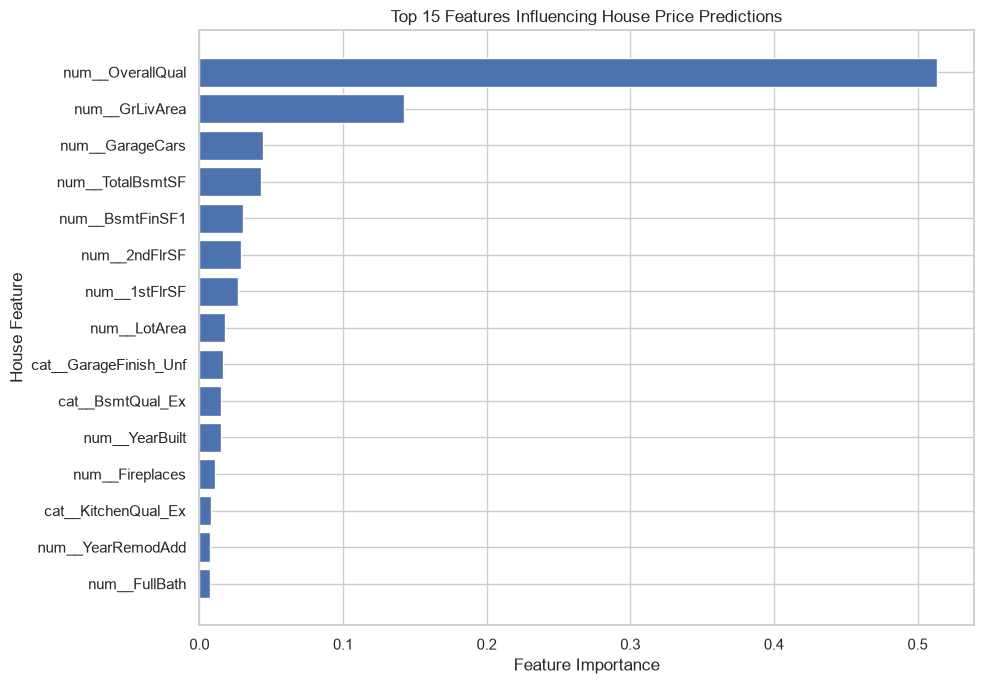

Feature-importance analysis completed.
CSV saved: outputs/feature_importance_xai.csv
Chart saved: outputs/feature_importance_xai.png

Top 10 features:
              Feature  Importance
     num__OverallQual    0.513633
       num__GrLivArea    0.142408
      num__GarageCars    0.044162
     num__TotalBsmtSF    0.042850
      num__BsmtFinSF1    0.030665
        num__2ndFlrSF    0.029224
        num__1stFlrSF    0.026761
         num__LotArea    0.018031
cat__GarageFinish_Unf    0.016698
     cat__BsmtQual_Ex    0.014974


In [87]:

import os
import joblib
import pandas as pd
import matplotlib.pyplot as plt

# Load the trained pipeline
model = joblib.load(
    "models/house_price_gradient_boosting.joblib"
)

preprocessor = model.named_steps["preprocessor"]
regressor = model.named_steps["model"]

# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()
importance_scores = regressor.feature_importances_

# Verify the mapping before creating the report
assert len(feature_names) == len(importance_scores), (
    "Feature names and importance scores do not match."
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_scores
}).sort_values("Importance", ascending=False)

# Create output folder if needed
os.makedirs("outputs", exist_ok=True)

# Save all feature importance scores
csv_path = "outputs/feature_importance_xai.csv"
importance_df.to_csv(csv_path, index=False)

# Plot the 15 most important features
top_features = importance_df.head(15).sort_values(
    "Importance", ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature Importance")
plt.ylabel("House Feature")
plt.title("Top 15 Features Influencing House Price Predictions")
plt.tight_layout()

chart_path = "outputs/feature_importance_xai.png"
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Feature-importance analysis completed.")
print("CSV saved:", csv_path)
print("Chart saved:", chart_path)
print("\nTop 10 features:")
print(importance_df.head(10).to_string(index=False))


In [88]:
from pathlib import Path

PROJECT_DIR = Path(r"C:\Users\amrut\Downloads\PRCP-1020-HousePricePred")

required_files = [
    "Data/data.csv",
    "models/house_price_gradient_boosting.joblib",
    "outputs/model_comparison.csv",
    "outputs/cross_validation_comparison.csv",
    "outputs/feature_importance_xai.csv",
    "outputs/feature_importance_xai.png",
    "outputs/prediction_error_analysis.csv",
    "outputs/top_error_analysis.csv",
    "PRCP-1020_House_Price_Prediction_Report.pdf",
    "README.md",
]

for file in required_files:
    path = PROJECT_DIR / file
    status = "FOUND" if path.is_file() else "MISSING"
    print(f"{status}: {file}")

FOUND: Data/data.csv
FOUND: models/house_price_gradient_boosting.joblib
FOUND: outputs/model_comparison.csv
FOUND: outputs/cross_validation_comparison.csv
FOUND: outputs/feature_importance_xai.csv
FOUND: outputs/feature_importance_xai.png
FOUND: outputs/prediction_error_analysis.csv
FOUND: outputs/top_error_analysis.csv
FOUND: PRCP-1020_House_Price_Prediction_Report.pdf
FOUND: README.md


In [89]:
from pathlib import Path

project_dir = Path(r"C:\Users\amrut\Downloads\PRCP-1020-HousePricePred")
readme_path = project_dir / "README.md"

readme_content = """# House Price Prediction

## Project Overview
This project predicts house sale prices using machine learning
on the Ames, Iowa housing dataset.

## Objectives
- Analyze housing data and identify important features.
- Explore relationships between property features and SalePrice.
- Train and compare regression models.
- Evaluate models using MAE, RMSE, R-squared, and cross-validation.
- Provide a prediction workflow for new house details.

## Models
- Random Forest Regressor
- Gradient Boosting Regressor

Gradient Boosting was selected based on the experiments
recorded in the notebook.

## Evaluation
The notebook includes model comparison, cross-validation,
feature importance, and prediction-error analysis.
Reported test-set comparisons are exploratory because the
test set was used during model selection.

## Important Features
Feature-importance analysis highlights:
- OverallQual
- GrLivArea
- GarageCars
- TotalBsmtSF
- BsmtFinSF1

Feature importance indicates predictive contribution, not causation.

## Project Structure
- Data/data.csv: housing dataset
- models/house_price_gradient_boosting.joblib: saved model
- outputs/: evaluation tables and visualizations
- PRCP-1020_House_Price_Prediction.ipynb: analysis and modeling
- PRCP-1020_House_Price_Prediction_Report.pdf: project report
- app.py: Streamlit prediction app

## Technologies
Python, pandas, NumPy, Matplotlib, Seaborn,
scikit-learn, Joblib, Streamlit, Jupyter Notebook.

## Run the Project
1. Install the required Python packages.
2. Run the notebook to reproduce the analysis and model.
3. Start the app from the project folder with:

   streamlit run app.py

## Limitations
- The dataset represents houses in Ames, Iowa.
- Predictions may not generalize to other locations or markets.
- Predictions are estimates, not professional property valuations.

## Future Improvements
- Evaluate the final model on a strictly untouched test set.
- Test additional regression algorithms and tuning strategies.
- Improve prediction intervals and model monitoring.
"""

readme_path.write_text(readme_content, encoding="utf-8")

print("README created:", readme_path.is_file())
print("Saved at:", readme_path)

README created: True
Saved at: C:\Users\amrut\Downloads\PRCP-1020-HousePricePred\README.md
